In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
house_price_df = pd.read_parquet("../parquet_exports/hpi_values.parquet")

In [3]:
house_price_df.head()

,Quarter,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,...,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom
0,1,1990,28.24,51.86,32.75,NaN,NaN,44.35,NaN,NaN,...,NaN,12.41,60.13,29.22,36.53,74.41,NaN,NaN,55.08,34.79
1,2,1990,28.50,58.38,32.67,NaN,NaN,41.38,NaN,NaN,...,NaN,12.98,64.52,29.72,37.27,75.45,NaN,NaN,55.14,34.49
2,3,1990,28.24,64.82,33.63,NaN,NaN,41.60,NaN,NaN,...,NaN,13.28,65.94,30.30,38.00,75.29,NaN,NaN,55.01,35.09
3,4,1990,28.41,65.45,34.01,NaN,NaN,41.93,NaN,NaN,...,NaN,13.55,68.80,30.82,37.45,73.62,NaN,NaN,54.76,34.55
4,1,1991,28.38,67.18,34.21,NaN,NaN,43.96,NaN,NaN,...,NaN,13.97,70.64,32.56,40.02,73.75,51.8,NaN,54.34,34.06


In [4]:
house_price_df.tail()

,Quarter,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,...,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom
136,1,2024,188.10,208.05,152.14,198.60,195.09,217.64,343.61,131.53,...,165.08,178.09,142.55,113.84,176.17,158.17,175.41,2747.61,228.71,162.59
137,2,2024,192.13,207.82,151.71,202.05,201.81,221.28,351.26,128.21,...,168.71,177.48,142.24,117.89,178.64,159.85,176.04,2914.85,229.86,164.59
138,3,2024,194.75,207.50,154.11,205.52,209.73,217.06,356.74,124.93,...,171.55,177.56,142.34,121.23,179.81,160.71,179.36,3093.81,231.92,168.74
139,4,2024,195.13,207.11,155.29,208.93,215.49,213.42,366.47,122.70,...,176.92,179.25,142.70,123.42,179.34,163.52,181.43,3300.23,234.44,169.58
140,1,2025,NaN,208.84,NaN,212.30,NaN,214.99,NaN,121.64,...,NaN,181.19,142.34,NaN,NaN,164.70,181.54,3622.43,234.42,171.74


In [5]:
def summarize_missing_by_country(df, time_cols=["Quarter", "Year"]):
    """
    Summarizes missing values per country column in a DataFrame.
    
    Parameters:
    - df: pd.DataFrame containing time columns and country columns
    - time_cols: list of columns to exclude from missing value summary
    
    Returns:
    - pd.DataFrame with total missing counts and percentage per country
    """
    country_cols = [col for col in df.columns if col not in time_cols]
    missing_counts = df[country_cols].isna().sum()
    missing_percent = df[country_cols].isna().mean() * 100

    summary_df = pd.DataFrame({
        "Missing Count": missing_counts,
        "Missing %": missing_percent.round(2)
    }).sort_values("Missing Count", ascending=False)

    return summary_df

In [6]:
summarize_missing_by_country(house_price_df)

,Missing Count,Missing %
Poland,81,57.45
Turkey,80,56.74
Romania,77,54.61
India,77,54.61
Czech-Republic,73,51.77
Philippines,73,51.77
Luxembourg,69,48.94
Slovenia,69,48.94
Slovakia,64,45.39
Latvia,64,45.39


**H1)** The previous output indicates that Poland will be the country that will most restrict us in the time range available to perform the correlation analysis. This statement is only correct due to the process of extracting and joining the values of this indicator. If indicators were downloaded for a country and those values were not available for a time range already existing in the master data frame, NaN values were assigned.

In [7]:
def get_missing_entries(df, time_cols=["Quarter", "Year"]):
    """
    Returns a DataFrame showing all missing values with their time context and country.
    
    Parameters:
    - df: pd.DataFrame with time columns and country columns
    - time_cols: list of columns to retain for context
    
    Returns:
    - pd.DataFrame with rows for each missing value, showing Year, Quarter, and Country
    """
    country_cols = [col for col in df.columns if col not in time_cols]
    melted = df.melt(id_vars=time_cols, value_vars=country_cols,
                     var_name="Country", value_name="Value")
    
    missing_df = melted[melted["Value"].isna()].sort_values(time_cols + ["Country"])
    return missing_df.reset_index(drop=True)

In [8]:
missing_entries = get_missing_entries(house_price_df)
missing_entries.head()

,Quarter,Year,Country,Value
0,1,1990,Brazil,NaN
1,1,1990,Bulgaria,NaN
2,1,1990,Chile,NaN
3,1,1990,China,NaN
4,1,1990,Croatia,NaN


In [17]:
mask = (
    (missing_entries["Country"] == "Poland") 
)

poland_missing = missing_entries[mask]
poland_missing.head()

,Quarter,Year,Country,Value
21,1,1990,Poland,NaN
51,1,1991,Poland,NaN
80,1,1992,Poland,NaN
109,1,1993,Poland,NaN
137,1,1994,Poland,NaN


In [29]:
poland_sorted = poland_missing.sort_values(by=["Quarter", "Year"], ascending=True)
poland_sorted

,Quarter,Year,Country,Value
21,1,1990,Poland,NaN
51,1,1991,Poland,NaN
80,1,1992,Poland,NaN
109,1,1993,Poland,NaN
137,1,1994,Poland,NaN
...,...,...,...,...
1544,4,2005,Poland,NaN
1553,4,2006,Poland,NaN
1560,4,2007,Poland,NaN
1564,4,2008,Poland,NaN


In [30]:
poland_sorted = poland_missing.sort_values(by=["Year", "Quarter"], ascending=True)
poland_sorted

,Quarter,Year,Country,Value
21,1,1990,Poland,NaN
436,2,1990,Poland,NaN
821,3,1990,Poland,NaN
1206,4,1990,Poland,NaN
51,1,1991,Poland,NaN
...,...,...,...,...
384,1,2009,Poland,NaN
798,2,2009,Poland,NaN
1183,3,2009,Poland,NaN
1567,4,2009,Poland,NaN


In [31]:
poland_sorted = poland_sorted.reset_index(drop=True)
poland_sorted

,Quarter,Year,Country,Value
0,1,1990,Poland,NaN
1,2,1990,Poland,NaN
2,3,1990,Poland,NaN
3,4,1990,Poland,NaN
4,1,1991,Poland,NaN
...,...,...,...,...
76,1,2009,Poland,NaN
77,2,2009,Poland,NaN
78,3,2009,Poland,NaN
79,4,2009,Poland,NaN


The previous outputs show us that Poland has no values for the house price index from 1990 to 2009 nor for 2025. Consequently, it has values in the range from 2010 to 2024, a desirable range since other values which we extracted with the crawlers are defined between 2014 and 2023.

### Let's delete all the data from the beginning until 2010

In [43]:
clean_df1 = house_price_df.copy()

In [44]:
clean_df1 = clean_df1[clean_df1["Year"] > 2009].reset_index(drop=True)

In [45]:
clean_df1

,Quarter,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,...,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom
0,1,2010,99.03,99.31,98.38,92.33,101.30,99.38,96.01,97.76,...,100.17,99.02,99.50,99.65,97.94,98.14,98.05,97.39,101.05,98.42
1,2,2010,100.97,99.71,99.16,97.49,100.67,101.15,100.25,100.01,...,100.75,99.74,100.01,101.27,99.14,98.95,98.83,99.31,101.37,100.25
2,3,2010,99.71,99.78,101.31,102.59,99.60,99.95,101.34,100.38,...,99.42,99.95,99.91,99.60,100.65,100.63,101.46,100.73,99.21,101.75
3,4,2010,100.29,101.20,101.15,107.59,98.43,99.52,102.39,101.86,...,99.65,101.29,100.57,99.49,102.28,102.28,101.66,102.57,98.37,99.58
4,1,2011,99.42,103.87,102.09,112.46,96.43,102.36,105.34,103.51,...,104.30,102.21,102.31,96.10,103.19,105.20,102.65,105.41,96.68,97.76
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
56,1,2024,188.10,208.05,152.14,198.60,195.09,217.64,343.61,131.53,...,165.08,178.09,142.55,113.84,176.17,158.17,175.41,2747.61,228.71,162.59
57,2,2024,192.13,207.82,151.71,202.05,201.81,221.28,351.26,128.21,...,168.71,177.48,142.24,117.89,178.64,159.85,176.04,2914.85,229.86,164.59
58,3,2024,194.75,207.50,154.11,205.52,209.73,217.06,356.74,124.93,...,171.55,177.56,142.34,121.23,179.81,160.71,179.36,3093.81,231.92,168.74
59,4,2024,195.13,207.11,155.29,208.93,215.49,213.42,366.47,122.70,...,176.92,179.25,142.70,123.42,179.34,163.52,181.43,3300.23,234.44,169.58


In [46]:
summarize_missing_by_country(clean_df1)

,Missing Count,Missing %
Australia,1,1.64
Belgium,1,1.64
Bulgaria,1,1.64
Colombia,1,1.64
Chile,1,1.64
Denmark,1,1.64
Czech-Republic,1,1.64
Cyprus,1,1.64
Croatia,1,1.64
Israel,1,1.64


This confirms hypothesis H1 detailed in the cells above. The following steps are followed:
1. Eliminate the last series with NaN values.
2. Add the values across the years so that the indices are by year and not by quarter.

In [47]:
clean_df2 = clean_df1[clean_df1["Year"] != 2025].reset_index(drop=True)
clean_df2

,Quarter,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,...,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom
0,1,2010,99.03,99.31,98.38,92.33,101.30,99.38,96.01,97.76,...,100.17,99.02,99.50,99.65,97.94,98.14,98.05,97.39,101.05,98.42
1,2,2010,100.97,99.71,99.16,97.49,100.67,101.15,100.25,100.01,...,100.75,99.74,100.01,101.27,99.14,98.95,98.83,99.31,101.37,100.25
2,3,2010,99.71,99.78,101.31,102.59,99.60,99.95,101.34,100.38,...,99.42,99.95,99.91,99.60,100.65,100.63,101.46,100.73,99.21,101.75
3,4,2010,100.29,101.20,101.15,107.59,98.43,99.52,102.39,101.86,...,99.65,101.29,100.57,99.49,102.28,102.28,101.66,102.57,98.37,99.58
4,1,2011,99.42,103.87,102.09,112.46,96.43,102.36,105.34,103.51,...,104.30,102.21,102.31,96.10,103.19,105.20,102.65,105.41,96.68,97.76
5,2,2011,98.74,101.04,102.80,117.13,94.73,105.84,111.51,104.28,...,104.00,102.89,104.70,94.95,103.21,106.79,104.94,108.39,97.21,98.42
6,3,2011,97.00,105.76,104.86,121.39,94.08,107.26,114.39,104.48,...,101.54,104.00,106.29,91.56,102.97,108.95,103.90,109.46,97.59,99.75
7,4,2011,96.22,106.23,104.58,125.11,92.72,107.54,117.68,104.20,...,101.02,105.26,107.61,86.81,100.95,109.10,105.56,111.94,97.48,98.25
8,1,2012,96.81,115.03,105.36,128.40,92.84,109.96,118.69,103.66,...,96.92,107.00,108.22,82.47,102.14,111.81,106.70,115.92,98.37,97.26
9,2,2012,97.19,116.76,105.59,131.52,93.25,112.09,122.21,103.11,...,98.04,107.72,108.53,79.80,103.64,113.15,106.18,119.61,100.87,99.09


In [48]:
summarize_missing_by_country(clean_df2)

,Missing Count,Missing %
Australia,0,0.0
Austria,0,0.0
Belgium,0,0.0
Brazil,0,0.0
Bulgaria,0,0.0
Canada,0,0.0
Chile,0,0.0
China,0,0.0
Colombia,0,0.0
Croatia,0,0.0


In [49]:
clean_df3 = clean_df2.groupby("Year").mean(numeric_only=True).reset_index()
clean_df3

,Year,Quarter,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,...,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom
0,2010,2.5,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,99.9975,100.0025,...,99.9975,100.0000,99.9975,100.0025,100.0025,100.0000,100.0000,100.0000,100.0000,100.0000
1,2011,2.5,97.8450,104.2250,103.5825,119.0225,94.4900,105.7500,112.2300,104.1175,...,102.7150,103.5900,105.2275,92.3550,102.5800,107.5100,104.2625,108.8000,97.2400,98.5450
2,2012,2.5,97.5325,117.1325,106.0150,133.0600,92.6900,110.6150,124.0250,103.4225,...,95.6325,108.4075,108.2500,78.7075,103.8650,113.7225,107.6325,120.6750,101.8200,98.9200
3,2013,2.5,103.9925,122.5900,107.5900,145.3175,90.6500,112.7600,136.5175,109.5550,...,90.6200,115.4075,107.8000,71.5250,109.2225,118.3000,115.9925,134.4625,111.8300,101.4550
4,2014,2.5,113.4075,126.7900,107.2250,155.3575,91.9475,118.8625,154.7200,112.3775,...,84.6400,123.9875,109.4325,71.7450,119.5200,121.4650,127.0725,151.2500,118.8800,109.6025
5,2015,2.5,123.6450,132.0575,109.1675,156.1650,94.5100,128.4275,174.9375,108.1225,...,85.3200,131.7975,113.0825,74.3200,135.2000,124.0775,135.9950,175.0850,125.1800,116.1250
6,2016,2.5,130.4450,141.7575,111.7175,151.9450,101.1475,148.6600,186.4325,115.2450,...,88.0950,138.2250,116.0900,77.7550,146.3425,124.3200,142.4050,197.4625,131.8825,124.2700
7,2017,2.5,141.3350,147.0825,115.6650,149.0200,109.9125,172.2950,201.6525,123.2850,...,95.3750,143.9375,117.5950,82.5700,156.0625,125.4250,146.4775,218.8125,139.6050,129.9250
8,2018,2.5,139.3050,157.2350,119.1575,149.8125,117.1525,178.2375,221.8375,129.8275,...,103.7050,148.9600,120.2225,88.1275,154.5975,129.1550,153.9000,235.9525,147.3475,134.0400
9,2019,2.5,133.6400,163.4250,123.6175,155.0550,124.2050,179.4000,240.5325,137.5800,...,110.6525,152.6875,121.9325,92.6875,158.4350,133.9900,155.0950,247.2950,153.1450,135.3700


In [50]:
clean_df4 = clean_df3.drop(columns="Quarter")
clean_df4

,Year,Australia,Austria,Belgium,Brazil,Bulgaria,Canada,Chile,China,Colombia,...,Slovenia,South-Africa,South-Korea,Spain,Sweden,Switzerland,Thailand,Turkey,USA,United-Kingdom
0,2010,100.0000,100.0000,100.0000,100.0000,100.0000,100.0000,99.9975,100.0025,100.0000,...,99.9975,100.0000,99.9975,100.0025,100.0025,100.0000,100.0000,100.0000,100.0000,100.0000
1,2011,97.8450,104.2250,103.5825,119.0225,94.4900,105.7500,112.2300,104.1175,107.8900,...,102.7150,103.5900,105.2275,92.3550,102.5800,107.5100,104.2625,108.8000,97.2400,98.5450
2,2012,97.5325,117.1325,106.0150,133.0600,92.6900,110.6150,124.0250,103.4225,118.7925,...,95.6325,108.4075,108.2500,78.7075,103.8650,113.7225,107.6325,120.6750,101.8200,98.9200
3,2013,103.9925,122.5900,107.5900,145.3175,90.6500,112.7600,136.5175,109.5550,130.0650,...,90.6200,115.4075,107.8000,71.5250,109.2225,118.3000,115.9925,134.4625,111.8300,101.4550
4,2014,113.4075,126.7900,107.2250,155.3575,91.9475,118.8625,154.7200,112.3775,140.7525,...,84.6400,123.9875,109.4325,71.7450,119.5200,121.4650,127.0725,151.2500,118.8800,109.6025
5,2015,123.6450,132.0575,109.1675,156.1650,94.5100,128.4275,174.9375,108.1225,152.9325,...,85.3200,131.7975,113.0825,74.3200,135.2000,124.0775,135.9950,175.0850,125.1800,116.1250
6,2016,130.4450,141.7575,111.7175,151.9450,101.1475,148.6600,186.4325,115.2450,167.4825,...,88.0950,138.2250,116.0900,77.7550,146.3425,124.3200,142.4050,197.4625,131.8825,124.2700
7,2017,141.3350,147.0825,115.6650,149.0200,109.9125,172.2950,201.6525,123.2850,178.5650,...,95.3750,143.9375,117.5950,82.5700,156.0625,125.4250,146.4775,218.8125,139.6050,129.9250
8,2018,139.3050,157.2350,119.1575,149.8125,117.1525,178.2375,221.8375,129.8275,188.2425,...,103.7050,148.9600,120.2225,88.1275,154.5975,129.1550,153.9000,235.9525,147.3475,134.0400
9,2019,133.6400,163.4250,123.6175,155.0550,124.2050,179.4000,240.5325,137.5800,198.3700,...,110.6525,152.6875,121.9325,92.6875,158.4350,133.9900,155.0950,247.2950,153.1450,135.3700


### Let's plot

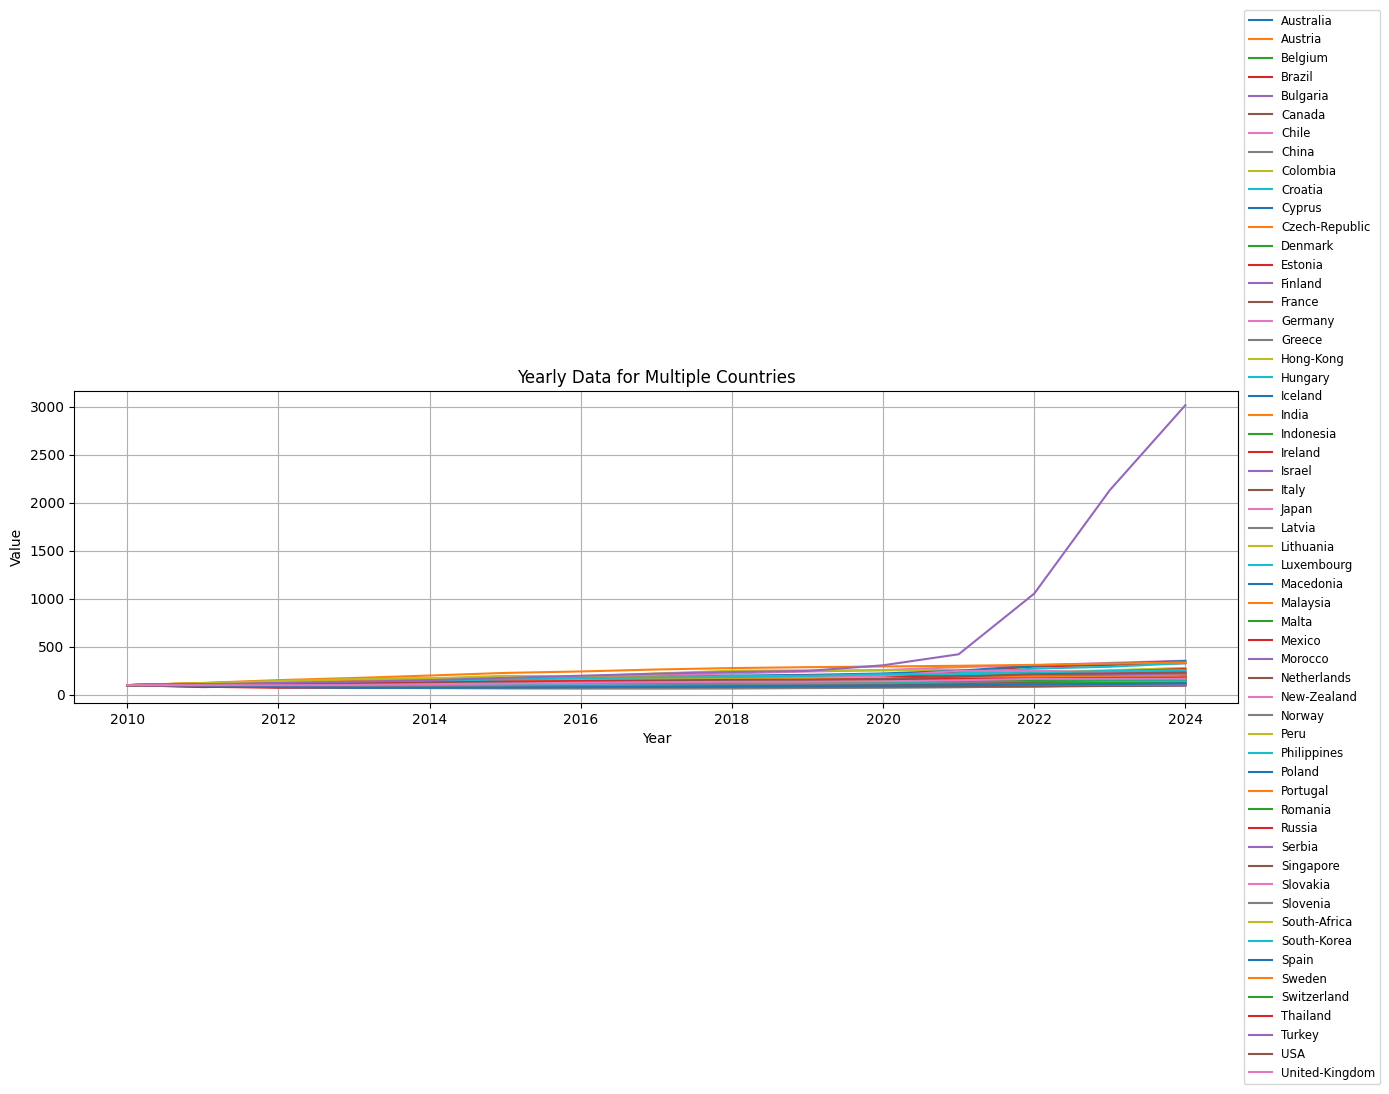

In [54]:
# Set figure size for better readability
plt.figure(figsize=(14, 8))

# Loop through each country column and plot its values over the years
for country in clean_df4.columns[1:]:  # Skip 'Year' column
    plt.plot(clean_df4["Year"], clean_df4[country], label=country)

# Add labels and title
plt.xlabel("Year")
plt.ylabel("Value")
plt.title("Yearly Data for Multiple Countries")
plt.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), ncol=1, fontsize="small")
plt.grid(True)
plt.tight_layout()

# Show the plot
plt.show()

We see that one country is completely outside the normal scale of evolution for this index. As this does not allow us to observe the visualization lines in detail, let's run another visualization, breaking down this country.

In [55]:
def plot_countries(df, exclude_country=None):
    """
    Plots country data over years, excluding one country if specified.
    
    Parameters:
    - df: DataFrame with 'Year' and country columns
    - exclude_country: str, name of the country to exclude from the plot
    """
    plt.figure(figsize=(14, 8))

    # Filter out the excluded country
    country_cols = [col for col in df.columns if col != "Year" and col != exclude_country]

    # Plot each remaining country
    for country in country_cols:
        plt.plot(df["Year"], df[country], label=country)

    plt.xlabel("Year")
    plt.ylabel("Value")
    title = "Yearly Data for Countries"
    if exclude_country:
        title += f" (excluding {exclude_country})"
    plt.title(title)
    plt.legend(loc="center left", bbox_to_anchor=(1.0, 0.5), ncol=1, fontsize="small")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

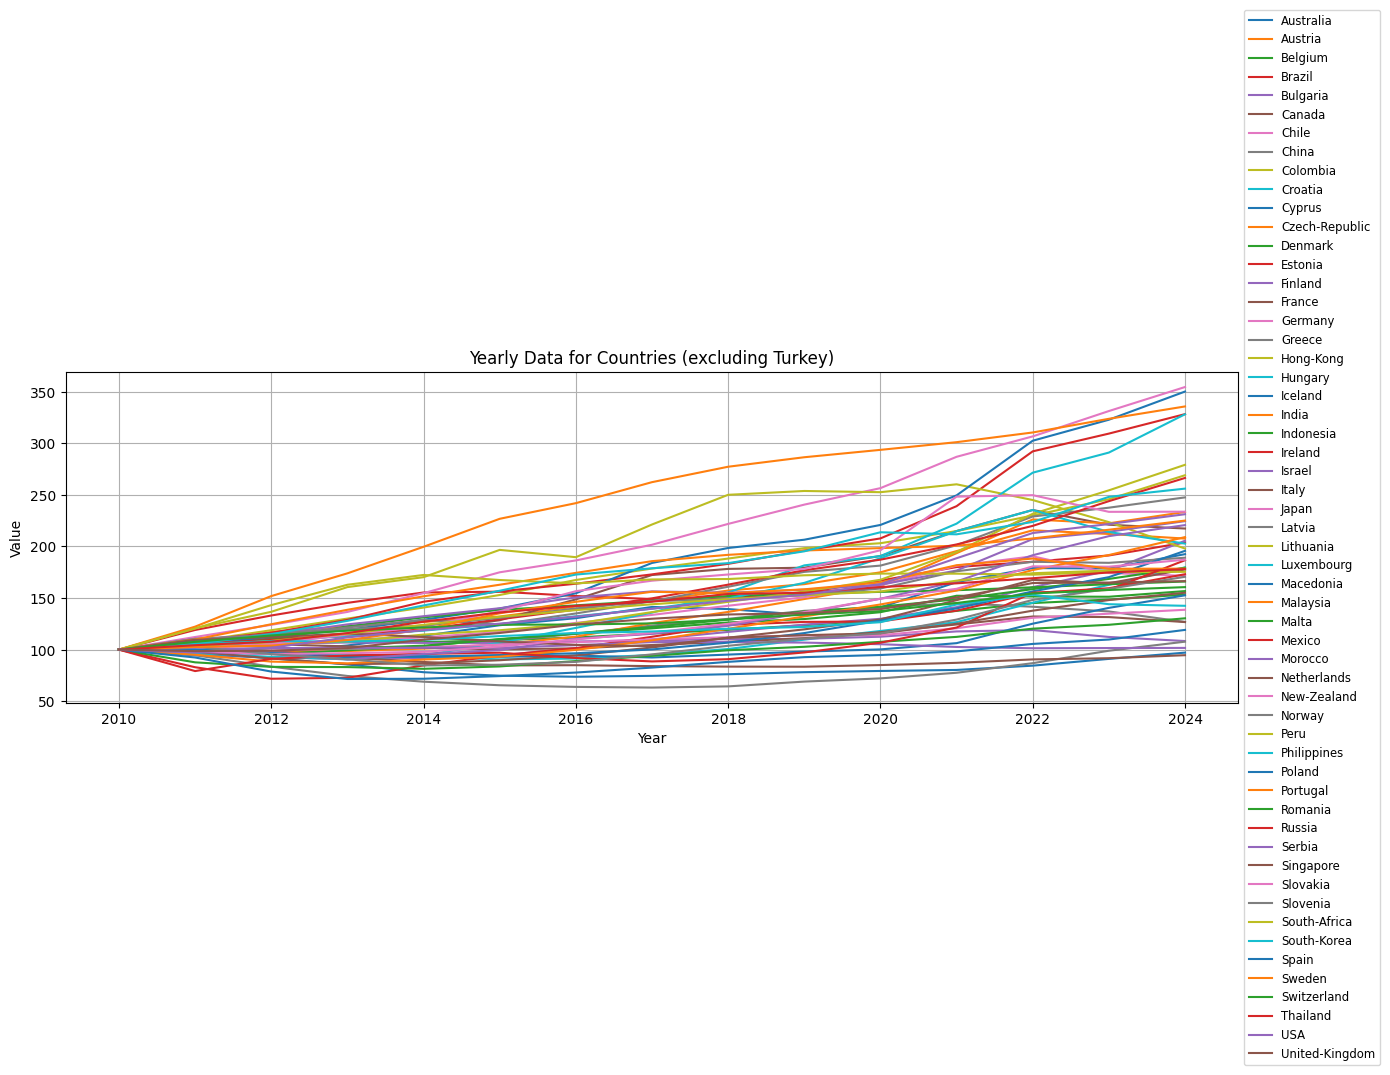

In [56]:
plot_countries(clean_df4, exclude_country="Turkey")

In [92]:
def plot_countries(df, exclude_country=None, legend_columns=4):
    """
    Plots country data over years, excluding one country if specified.
    Displays the legend at the top in multiple columns.
    
    Parameters:
    - df: DataFrame with 'Year' and country columns
    - exclude_country: str, name of the country to exclude from the plot
    - legend_columns: int, number of columns in the legend
    """
    plt.figure(figsize=(14, 8))

    # Filter out the excluded country
    country_cols = [col for col in df.columns if col != "Year" and col != exclude_country]

    # Plot each remaining country
    for country in country_cols:
        plt.plot(df["Year"], df[country], label=country)

    plt.xlabel("Year")
    plt.ylabel("Value")
    title = "Yearly Data for Countries"
    if exclude_country:
        title += f" (excluding {exclude_country})"
    plt.title(title)

    # Stylized legend at the top
    plt.legend(loc="right", bbox_to_anchor=(0.5, 1.3),
               ncol=legend_columns, fontsize="small", frameon=False)

    plt.grid(True)
    plt.tight_layout()
    plt.show()

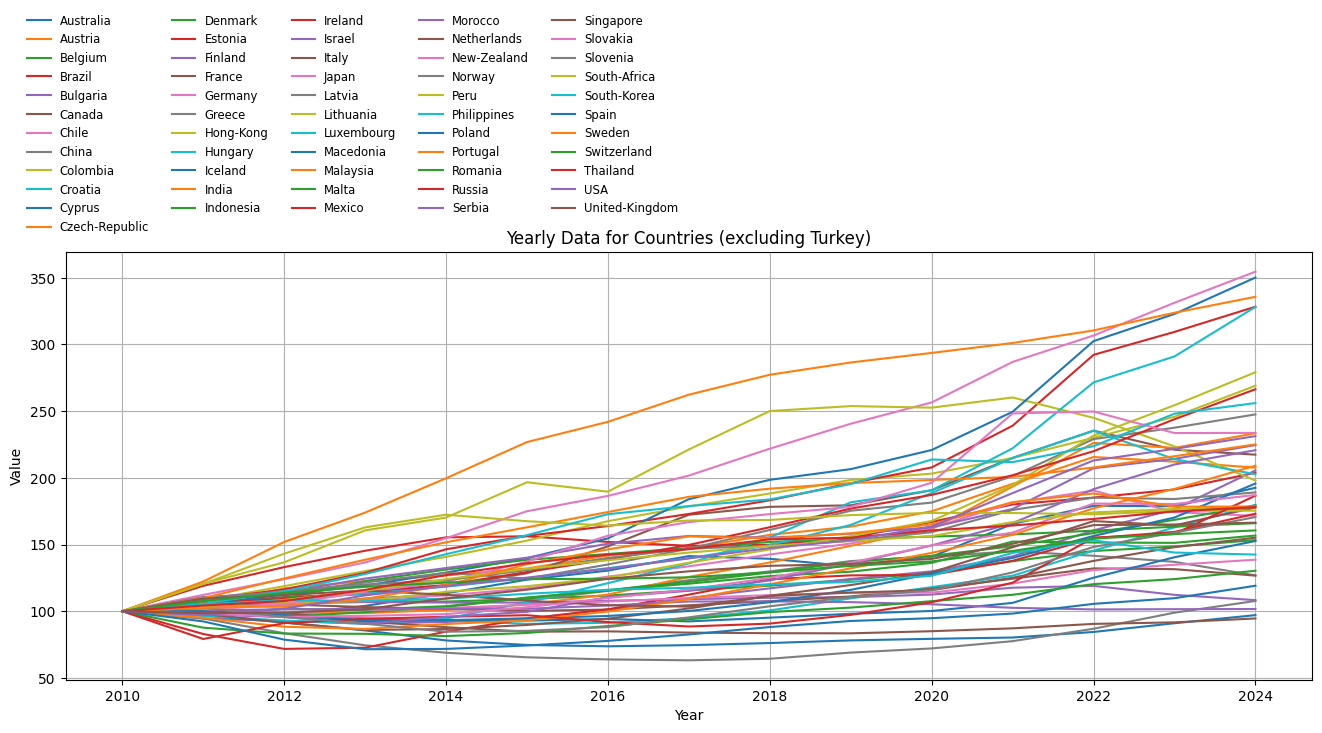

In [93]:
plot_countries(clean_df4, exclude_country="Turkey", legend_columns=5)

In [94]:
# Guardar como archivo Parquet
clean_df4.to_parquet("../data/clean_hpi.parquet", index=False)